# Partial Coherence

> Georgios Varnavides | Oct 8 2026  
>
> Sample: a 2-unit-cell SrTiO$_3$ film, and two such films twisted by 36.87 deg, 7.81 A apart  
> Sampling conditions: 0.2 A step-size  
> Imaging conditions: 300 kV, 25 mrad, 100 A underfocus at the mid-plane  
> Partial coherence: 50 A focal spread and a 0.25 A source for the film, 20 A focal spread for the bilayer  
> Dose conditions: 1e5 and 1e4 e/A2  

The models so far assume a perfectly coherent probe. A real source has a spread of energies and
a finite size, and both average the data incoherently. This notebook adds them to the forward
model, either as two parametric envelopes or as the incoherent modes of a mixed-state probe, and
shows which kernels gain from them, how the residual fits the focal spread, and what they do to
the slices of `ptycho_direct_08_multislice`. The datasets are simulated in
`simulation_notebooks/twisted-srtio3-membranes.ipynb`.

In [1]:
# %load_ext autoreload
# %autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch

import quantem as em

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def add_poisson_noise(dataset, electrons_per_area, seed=2025):
    rng = np.random.default_rng(seed)
    electrons_per_probe = electrons_per_area * np.prod(dataset.sampling[-4:-2])
    dataset_noisy = dataset.copy()
    dataset_noisy.array = rng.poisson(dataset.array * electrons_per_probe).astype(np.float32)
    return dataset_noisy


def correlation(a, b):
    a, b = (np.asarray(x.cpu() if hasattr(x, "cpu") else x, dtype=np.float64) for x in (a, b))
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


def correlation_table(images, truth):
    """Correlation of each image (rows) with each film (columns)."""
    return np.array([[correlation(image, film) for film in truth] for image in images]).round(3)

In [4]:
energy = 300e3
semiangle_cutoff = 25
C10 = -100
spacing = 7.81

kwargs = dict(
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    rotation_angle=0,
    aberration_coefs={"C10": C10},
    verbose=False,
    # device='gpu',
)

## The forward model

A spread of defocus $\sigma_f$, from the energy spread of the source and lens instabilities,
and a finite source, which spreads the probe position by $s$ rms per axis, both average the
data incoherently. For Gaussian distributions the averages have a closed form, in which each term of
the overlap function at scan frequency $\mathbf{q}$ and bright-field pixel $\mathbf{k}$ is
multiplied by

$$\exp\left(-2\pi^2 \left(s^2 |\mathbf{q}|^2 + \sigma_f^2 q_z^2\right)\right),$$

where $q_z$ is the term's own depth frequency, $\lambda (|\mathbf{k}|^2 - |\mathbf{k} -
\mathbf{q}|^2)/2$ or $\lambda (|\mathbf{k} + \mathbf{q}|^2 - |\mathbf{k}|^2)/2$. Every
constructor takes `focal_spread` and `source_size`, in Angstrom rms, and both are also settable
properties.

In [5]:
film = em.core.io.load("../../data/STO-film_300kV_25mrad_partial-coherence.zip")
film_truth = em.core.io.load("../../data/STO-film_truth.zip").array[0]
print(film.metadata)

kernels = ["ssb", "obf", "wiener", "wdd"]
models = {
    "coherent": dict(),
    "focal spread": dict(focal_spread=50),
    "focal spread and source": dict(focal_spread=50, source_size=0.25),
}


def coherence_table(dose):
    noisy_film = add_poisson_noise(film, dose)
    print(f"{dose:g} e/A2" + "".join(f"{kernel:>9}" for kernel in kernels))
    for label, model in models.items():
        recon = em.diffractive_imaging.DirectPtychography.from_dataset4d(noisy_film, **model, **kwargs)
        row = []
        for kernel in kernels:
            row.append(correlation(recon.reconstruct(deconvolution_kernel=kernel).corrected_bf, film_truth))
        print(f"{label:>23}" + "".join(f"{value:9.3f}" for value in row))


coherence_table(1e5)

{'r_to_q_rotation_cw_deg': None, 'ellipticity': None, 'energy': 300000.0, 'semiangle_cutoff': 25, 'C10': -100, 'focal_spread': 50, 'source_size': 0.25}
100000 e/A2      ssb      obf   wiener      wdd
               coherent    0.752    0.745    0.760    0.632
           focal spread    0.752    0.770    0.809    0.781
focal spread and source    0.752    0.770    0.869    0.826


The table gives each reconstruction's correlation with the true phase.

- SSB keeps its unit-modulus weights from the coherent overlap and does not change.
- OBF weights every bright-field pixel by its own overlap function, so modelling the focal
  spread, which weakens some pixels more than others, improves it. The source envelope depends
  on $\mathbf{q}$ alone, and scales every pixel at that frequency alike, so OBF ignores it.
- The Wiener estimate and WDD aim at the object itself, so they also divide the source
  envelope back out where the signal allows.

At ten times lower dose there is less signal to divide the envelope out of:

In [6]:
coherence_table(1e4)

10000 e/A2      ssb      obf   wiener      wdd
               coherent    0.700    0.668    0.726    0.345
           focal spread    0.700    0.701    0.774    0.530
focal spread and source    0.700    0.702    0.776    0.752


At this dose the source term adds little to the Wiener estimate (0.774 to 0.776), while WDD
still gains from it (0.530 to 0.752).

### Fitting the focal spread, but not the source size

The focal spread changes how the bright-field pixels relate to each other, so the residual
depends on it and can fit it. The source size scales every pixel alike and leaves the residual
unchanged, so it has to come from a calibration.

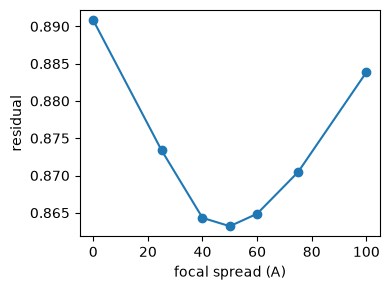

In [7]:
direct_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(film, 1e5), **kwargs
)

focal_spreads = [0, 25, 40, 50, 60, 75, 100]
residuals = []
for focal_spread in focal_spreads:
    direct_ptycho.focal_spread = focal_spread
    residuals.append(direct_ptycho.reconstruct(deconvolution_kernel="obf").residual_loss())

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(focal_spreads, residuals, "o-")
ax.set_xlabel("focal spread (A)")
ax.set_ylabel("residual")
fig.tight_layout()

In [8]:
direct_ptycho.focal_spread = 50
print(f"{'source size':>12} {'residual':>9} {'wiener':>7}")
for source_size in (0, 0.125, 0.25, 0.375, 0.5):
    direct_ptycho.source_size = source_size
    residual = direct_ptycho.reconstruct(deconvolution_kernel="obf").residual_loss()
    wiener = correlation(direct_ptycho.reconstruct(deconvolution_kernel="wiener").corrected_bf, film_truth)
    print(f"{source_size:12.3f} {residual:9.5f} {wiener:7.3f}")
direct_ptycho.source_size = 0

 source size  residual  wiener
       0.000   0.86320   0.809
       0.125   0.86320   0.825
       0.250   0.86320   0.869
       0.375   0.86320   0.642
       0.500   0.86320   0.116


Overestimating the source size over-sharpens the Wiener estimate, which then divides by an
envelope smaller than the data's and amplifies the noise at high spatial frequencies. When the
source size is uncertain, underestimating it is the safer error.

### A mixed-state probe

The parametric envelope assumes Gaussian distributions. The alternative is a measured
mixed-state probe, such as an iterative ptychographic reconstruction with several modes
returns: `fourier_probe` accepts the incoherent modes as an `(M, Ny, Nx)` array, and the overlap
function is then summed over them. To compare the two, we build the modes from the same 50 A
focal spread, as seven probes at Gauss-Hermite defoci, each weighted by the square root of its
quadrature weight.

An empirical probe is sampled on the detector grid, whose field of view here is half the
scan's, so it is refined twice with `resampled_to` before use.

In [9]:
from quantem.diffractive_imaging.complex_probe import FourierProbe

full_detector = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(film, 1e5), crop_bf_mask=False, **kwargs
)

nodes, weights = np.polynomial.hermite_e.hermegauss(7)
weights = weights / weights.sum()

kx = torch.fft.fftfreq(full_detector.gpts[0], full_detector.sampling[0])
ky = torch.fft.fftfreq(full_detector.gpts[1], full_detector.sampling[1])
kx, ky = torch.meshgrid(kx, ky, indexing="ij")

modes = []
for node, weight in zip(nodes, weights):
    probe = FourierProbe.from_aberrations(
        full_detector.wavelength,
        semiangle_cutoff,
        full_detector.angular_sampling,
        {"C10": C10 + 50 * node},
    )
    modes.append(np.sqrt(weight) * probe.at(kx, ky))
modes = torch.stack(modes).to(torch.complex64)

mixed_state = FourierProbe.from_array(
    modes, full_detector.reciprocal_sampling, full_detector.wavelength
).resampled_to(tuple(s / 2 for s in full_detector.reciprocal_sampling))

print(f"{'probe':>24} {'residual':>9} {'obf':>6} {'wiener':>7}")
for label, probe, focal_spread in (
    ("coherent", None, 0),
    ("focal spread envelope", None, 50),
    ("seven defocus modes", mixed_state, 0),
):
    full_detector.fourier_probe = probe
    full_detector.focal_spread = focal_spread
    obf = full_detector.reconstruct(deconvolution_kernel="obf")
    residual, obf = obf.residual_loss(), correlation(obf.corrected_bf, film_truth)
    wiener = correlation(full_detector.reconstruct(deconvolution_kernel="wiener").corrected_bf, film_truth)
    print(f"{label:>24} {residual:9.5f} {obf:6.3f} {wiener:7.3f}")

                   probe  residual    obf  wiener
                coherent   0.89082  0.745   0.760
   focal spread envelope   0.86320  0.770   0.809
     seven defocus modes   0.86340  0.769   0.803


Seven modes reproduce the envelope closely.

### Partial coherence and slices

The focal spread also damps the depth information, which is carried by the same $q_z$ as its
envelope. On the twisted bilayer simulated with a 20 A focal spread:

In [10]:
bilayer = em.core.io.load("../../data/STO-twisted-bilayer_300kV_25mrad_focal-spread.zip")
bilayer_truth = em.core.io.load("../../data/STO-twisted-bilayer_truth.zip").array
noisy_bilayer = add_poisson_noise(bilayer, 1e5)

for focal_spread in (0, 20):
    recon = em.diffractive_imaging.DirectPtychography.from_dataset4d(
        noisy_bilayer, focal_spread=focal_spread, **kwargs
    )
    for kernel in ("obf", "wiener"):
        recon.reconstruct(
            deconvolution_kernel=kernel,
            obj_type="complex",
            num_slices=2,
            slice_thicknesses=spacing,
            slice_mode="joint",
        )
        print(f"focal spread {focal_spread:>2} A, {kernel:>6}: "
              f"{correlation_table(recon.corrected_bf, bilayer_truth).tolist()}")

focal spread  0 A,    obf: [[0.751, 0.2], [0.052, 0.642]]
focal spread  0 A, wiener: [[0.722, 0.211], [0.032, 0.637]]
focal spread 20 A,    obf: [[0.734, 0.017], [0.061, 0.768]]
focal spread 20 A, wiener: [[0.808, 0.064], [0.107, 0.844]]


Modelling the focal spread removes most of the exit film from slice 0 and raises slice 1's
correlation with its own film, and the Wiener estimate gains the most. A 50 A focal spread,
as on the single film, removes so much of the depth information at this spacing that neither
model separates the two films.

## Summary

| option | call |
|---|---|
| focal spread | `from_dataset4d(..., focal_spread=50)`, or `recon.focal_spread = 50`, which the residual can fit |
| source size | `from_dataset4d(..., source_size=0.25)`, from a calibration, divided out by the Wiener and WDD kernels |
| mixed-state probe | `recon.fourier_probe = FourierProbe.from_array(modes, ...)`, with `resampled_to` when the scan's field of view is larger |

The last two notebooks, `ptycho_direct_10_ungridded_scans` and `ptycho_direct_11_sparse_frames`,
reconstruct scans whose positions are not on a regular grid, and the event lists of
event-driven detectors.